In [1]:
from copy import deepcopy
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import seaborn as sns

In [2]:
with open("/data_vol/FINAL/L_cell_type_colors.json", "r") as f:
    cell_type_colors = json.load(f)
cell_type_colors["Cohort"] = {"ICC": "gray"}

In [3]:
# traits
immune_traits = ["Celiac", "IBD_deLange2017",
                 "Rheumatoid_Arthritis", "Crohns_Disease",
                 "Lupus", "Primary_biliary_cirrhosis", "Ulcerative_Colitis"]
non_immune_traits = ["Alzheimer", "Bipolar_Disorder", "Height1",
                     "Type_2_Diabetes", "BMI1", 
                     "Coronary_Artery_Disease", "Schizophrenia"]
traits_dict = {"Immune": immune_traits, "Non-immune": non_immune_traits}
all_traits = np.concatenate([immune_traits, non_immune_traits])

results_dir="/data_vol/analysis_outputs/ldsc/out"
fig_dir="/data_vol/analysis_outputs/ldsc/figures"

### Overall peak and gene heritability visualizations

In [4]:
# read in results

ldsc_results = []
cell_type_specific_peak_cluster_annots = [f"kmeans_16_L2_permissive_peaks_L2_cell_types_cluster_{i}" for i in range(16)]
annots = ["L2_permissive", "ICC_all_expressed_genes_slop_100kb", "kmeans_16_L2_permissive_peaks_L2_cell_types_non_shared"] + cell_type_specific_peak_cluster_annots
for trait in all_traits: 
    for annot in annots: 
        df = pd.read_csv(
            f"{results_dir}/{trait}_{annot}.results",
            sep="\t", index_col=0)
        df = df[-1::]
        
        df["Trait"] = trait
        if trait in immune_traits:
            df["Trait type"] = "Immune"
        else:
            df["Trait type"] = "Non-immune"

        if annot == "L2_permissive":
            df["Annotation"] = "All ATAC-seq peaks"
        elif annot == "ICC_all_expressed_genes_slop_100kb":
            df["Annotation"] = f"All expressed genes (100kb window)"
        elif annot == "kmeans_16_L2_permissive_peaks_L2_cell_types_non_shared":
            df["Annotation"] = "Non-cell type shared peaks"
        else:
            df["Annotation"] = f"Peak cluster {annot.split('_')[-1]}"
        ldsc_results.append(df) 

        if annot == "kmeans_16_L2_permissive_peaks_L2_cell_types_cluster_1":
            df = deepcopy(df)
            df["Annotation"] = "Cell type shared peaks"
            ldsc_results.append(df) 

ldsc_results = pd.concat(ldsc_results)
ldsc_results.reset_index(inplace=True, drop=True)
ldsc_results["Annotation label"] = ldsc_results["Annotation"] + " - " + ldsc_results["Prop._SNPs"].apply(lambda x: round(x*100, 2)).astype(str) + "% of SNPs"

ldsc_results_pivot = ldsc_results.pivot(index="Annotation label", columns="Trait", values="Prop._h2")
ldsc_results_pivot.clip(lower=0, inplace=True)

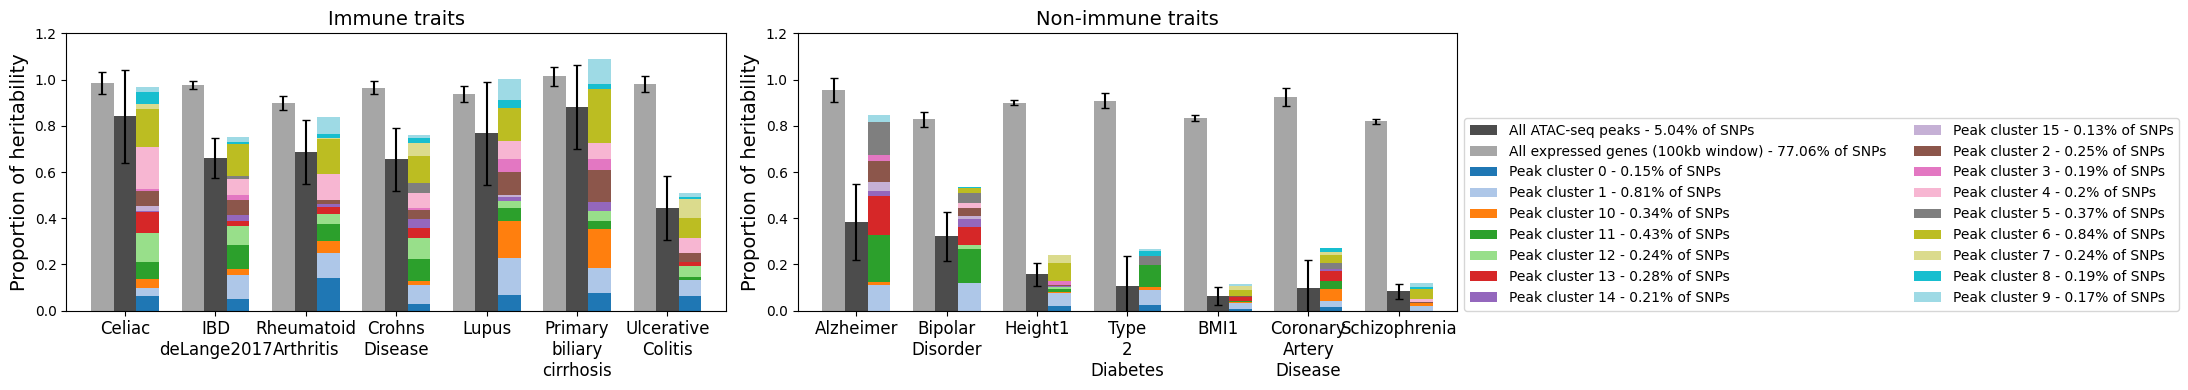

In [22]:
width = 0.25

fig, ax = plt.subplots(1, 2, figsize=(22, 4))
for i, (trait_type, traits) in enumerate(traits_dict.items()):
    for j, annot in enumerate(["All ATAC-seq peaks", "All expressed genes (100kb window)"]):
        prop_snps = ldsc_results.loc[ldsc_results["Annotation"] == annot, "Prop._SNPs"].unique()[0]
        prop_h2 = [ldsc_results.loc[(ldsc_results["Trait"] == trait) & 
                                    (ldsc_results["Annotation"] == annot), "Prop._h2"].iloc[0]
                for trait in traits]
        prop_h2_std = [ldsc_results.loc[(ldsc_results["Trait"] == trait) & 
                                        (ldsc_results["Annotation"] == annot), "Prop._h2_std_error"].iloc[0]
                    for trait in traits]
        ax[i].bar(np.arange(len(traits)) - (j+1)*width, prop_h2, width=width, yerr=prop_h2_std,
                  capsize=3, color="black", alpha=0.7-(j*0.35), label=f"{annot} - {round(prop_snps*100, 2)}% of SNPs")
    
    ldsc_results_pivot.loc[ldsc_results_pivot.index.str.contains("cluster"), 
                           traits].T.plot.bar(stacked=True, cmap="tab20", ax=ax[i], legend=False, width=width)
    
    ax[i].set_title(f"{trait_type} traits", fontsize=14)
    ax[i].set_ylabel(f"Proportion of heritability", fontsize=14)
    ax[i].set_xlabel("")

    ax[i].set_xlim(-0.9, len(traits)-0.6)
    ax[i].set_ylim(0, 1.2)

    ax[i].set_xticks(np.arange(len(traits))-width)
    ax[i].set_xticklabels([t.replace("_", "\n") for t in traits], rotation=0, fontsize=12)

plt.legend(loc=(1.01, 0), ncol=2)
plt.tight_layout()
plt.savefig(f"{fig_dir}/cell_type_specific_peak_heritability_stacked_bar_short.pdf", dpi=300)
plt.savefig(f"{fig_dir}/cell_type_specific_peak_heritability_stacked_bar_short.png", dpi=300)

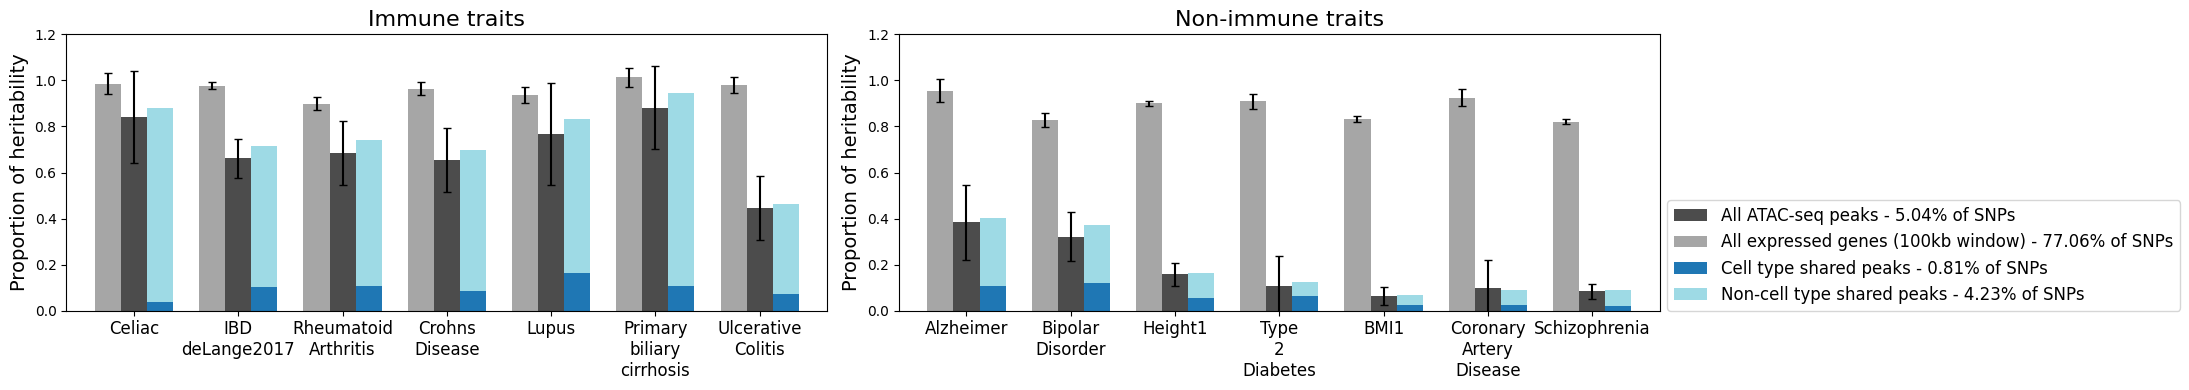

In [19]:
width = 0.25

fig, ax = plt.subplots(1, 2, figsize=(22, 4))
for i, (trait_type, traits) in enumerate(traits_dict.items()):
    for j, annot in enumerate(["All ATAC-seq peaks", "All expressed genes (100kb window)"]):
        prop_snps = ldsc_results.loc[ldsc_results["Annotation"] == annot, "Prop._SNPs"].unique()[0]
        prop_h2 = [ldsc_results.loc[(ldsc_results["Trait"] == trait) & 
                                    (ldsc_results["Annotation"] == annot), "Prop._h2"].iloc[0]
                for trait in traits]
        prop_h2_std = [ldsc_results.loc[(ldsc_results["Trait"] == trait) & 
                                        (ldsc_results["Annotation"] == annot), "Prop._h2_std_error"].iloc[0]
                    for trait in traits]
        ax[i].bar(np.arange(len(traits)) - (j+1)*width, prop_h2, width=width, yerr=prop_h2_std,
                  capsize=3, color="black", alpha=0.7-(j*0.35), label=f"{annot} - {round(prop_snps*100, 2)}% of SNPs")
    
    ldsc_results_pivot.loc[ldsc_results_pivot.index.str.contains("shared"), 
                           traits].T.plot.bar(stacked=True, cmap="tab20", ax=ax[i], legend=False, width=width)
    
    ax[i].set_title(f"{trait_type} traits", fontsize=16)
    ax[i].set_ylabel(f"Proportion of heritability", fontsize=14)
    ax[i].set_xlabel("")

    ax[i].set_xlim(-0.9, len(traits)-0.6)
    ax[i].set_ylim(0, 1.2)

    ax[i].set_xticks(np.arange(len(traits))-width)
    ax[i].set_xticklabels([t.replace("_", "\n") for t in traits], rotation=0, fontsize=12)

plt.legend(loc=(1.01, 0), fontsize=12)
plt.tight_layout()
plt.savefig(f"{fig_dir}/cell_type_shared_peak_heritability_stacked_bar_short.pdf", dpi=300)
plt.savefig(f"{fig_dir}/cell_type_shared_peak_heritability_stacked_bar_short.png", dpi=300)

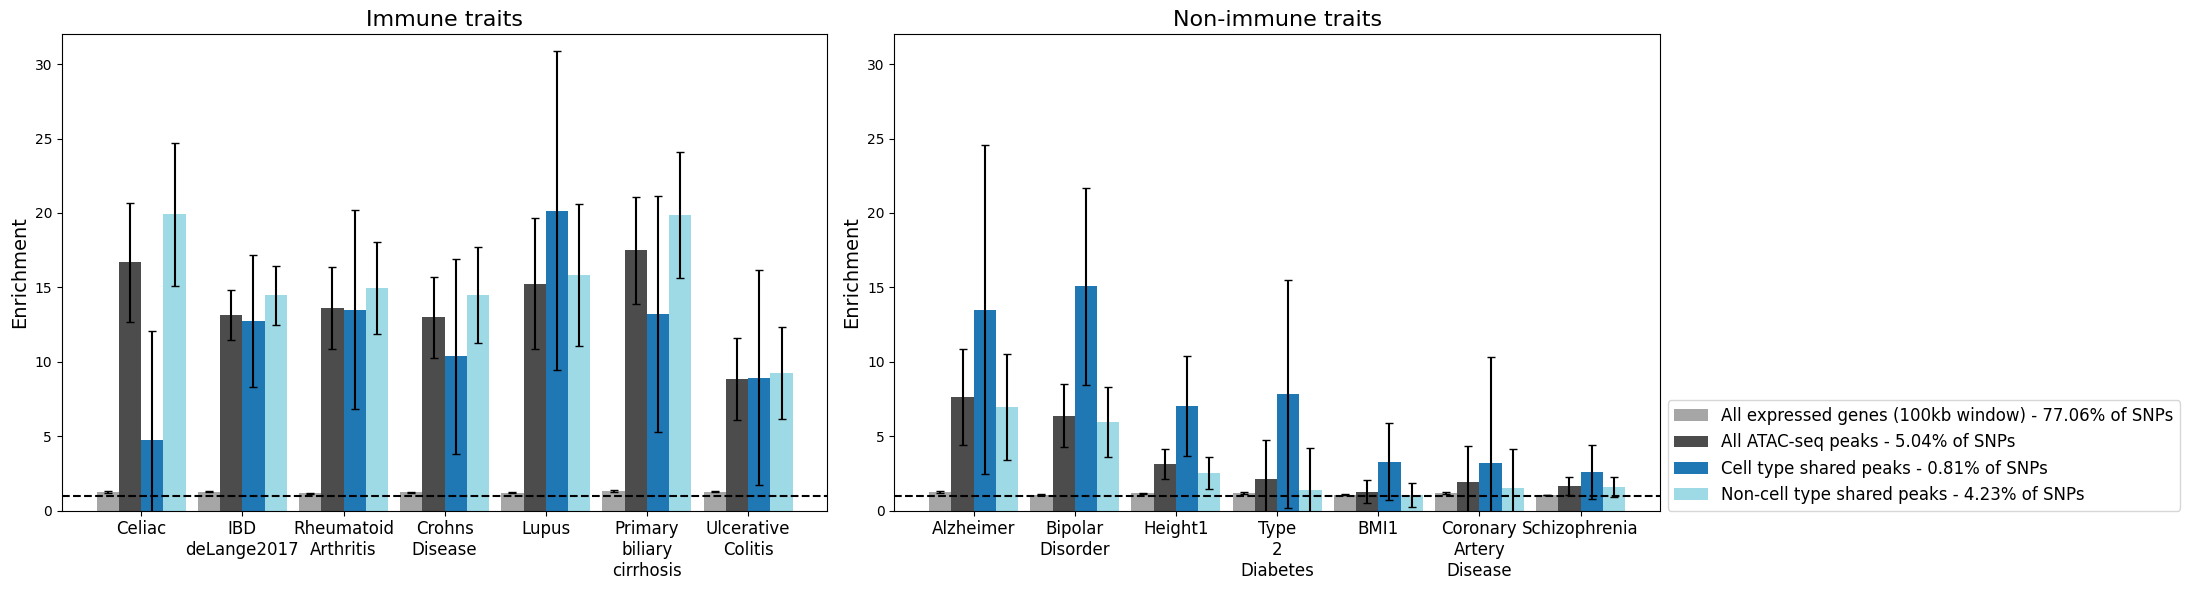

In [ ]:
width = 0.22
colors = [("black", 0.35), ("black", 0.7), (plt.get_cmap("tab20")(0), 1), (plt.get_cmap("tab20")(19), 1)]

fig, ax = plt.subplots(1, 2, figsize=(22, 4))
for i, (trait_type, traits) in enumerate(traits_dict.items()):
    for j, annot in enumerate(["All expressed genes (100kb window)", "All ATAC-seq peaks", "Cell type shared peaks", "Non-cell type shared peaks"]):
        prop_snps = ldsc_results.loc[ldsc_results["Annotation"] == annot, "Prop._SNPs"].unique()[0]
        prop_h2 = [ldsc_results.loc[(ldsc_results["Trait"] == trait) & 
                                    (ldsc_results["Annotation"] == annot), "Enrichment"].iloc[0]
                for trait in traits]
        prop_h2_std = [ldsc_results.loc[(ldsc_results["Trait"] == trait) & 
                                        (ldsc_results["Annotation"] == annot), "Enrichment_std_error"].iloc[0]
                    for trait in traits]
        ax[i].bar(np.arange(len(traits)) + j*width, prop_h2, width=width, yerr=prop_h2_std,
                  capsize=3, color=colors[j][0], alpha=colors[j][1], label=f"{annot} - {round(prop_snps*100, 2)}% of SNPs")

    
    xlims = ax[i].get_xlim()
    ax[i].hlines(y=1, xmin=xlims[0], xmax=xlims[1], color="black", linestyle="--")
    ax[i].set_title(f"{trait_type} traits", fontsize=16)
    ax[i].set_ylabel(f"Enrichment", fontsize=14)
    ax[i].set_xlabel("")
    ax[i].set_xlim(xlims[0], xlims[1])
    ax[i].set_ylim(0, 32)

    ax[i].set_xticks(np.arange(len(traits))+1.5*width)
    ax[i].set_xticklabels([t.replace("_", "\n") for t in traits], rotation=0, fontsize=12)

plt.legend(loc=(1.01, 0), fontsize=12)
plt.tight_layout()
plt.savefig(f"{fig_dir}/cell_type_shared_peak_heritability_enrichment_bar_short.pdf", dpi=300)
plt.savefig(f"{fig_dir}/cell_type_shared_peak_heritability_enrichment_bar_short.png", dpi=300)

### Experiment with QTL heritability visualizations

In [4]:
cell_types_dict = {"Cohort": ["ICC"],
                   "L1_manual": ["B", "CD4T", "CD8T", "NK", "cDC", "cM", "gdT", "ncM"],
                   "L2_manual": ["B_Memory", "B_Naive", "CD4T_Memory", "CD4T_Naive", "CD8T_Memory", "CD8T_Naive", "MAIT", "NK_dim", "Treg", "cDC2", "cM", "gdT", "ncM"]}

In [ ]:
# read in results

ldsc_results = []
for trait in all_traits:
    for modality in ["rna", "atac"]:
        for level in cell_types_dict.keys():
            for cell_type in cell_types_dict[level]:
                # for annot in ["significant", "significant.SuSiE_CS", "significant.SuSiE_PIP_0.3"]:
                for annot in ["significant",]:
                    df = pd.read_csv(
                        f"{results_dir}/{trait}_{modality}_{level}_{cell_type}.cis_qtl_pairs.{annot}.results",
                        sep="\t", index_col=0)
                    df = df[-1::]
                    df["Trait"] = trait.replace("_", "\n")
                    if trait in immune_traits:
                        df["Trait type"] = "Immune"
                    else:
                        df["Trait type"] = "Non-immune"
                    df["Modality"] = modality
                    df["Level"] = level
                    df["Cell type"] = cell_type
                    df["Annot"] = annot
                    df["Annotation"] = f"{modality} QTLs - {annot} - {level} - {cell_type}"
                    ldsc_results.append(df)   
    
ldsc_results = pd.concat(ldsc_results)
ldsc_results.reset_index(inplace=True, drop=True)

In [ ]:
traits_dict = {"Immune": ldsc_results[ldsc_results["Trait type"] == "Immune"]["Trait"].unique(),
               "Non-immune": ldsc_results[ldsc_results["Trait type"] == "Non-immune"]["Trait"].unique()}
color_palette = cell_type_colors["Cohort"] | cell_type_colors["L1"] | cell_type_colors["L2"]

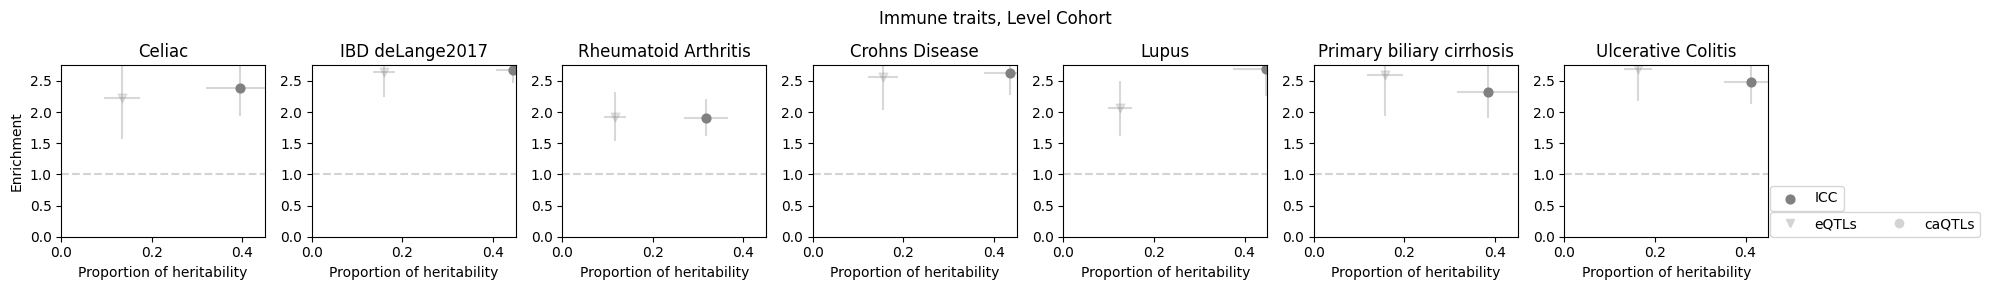

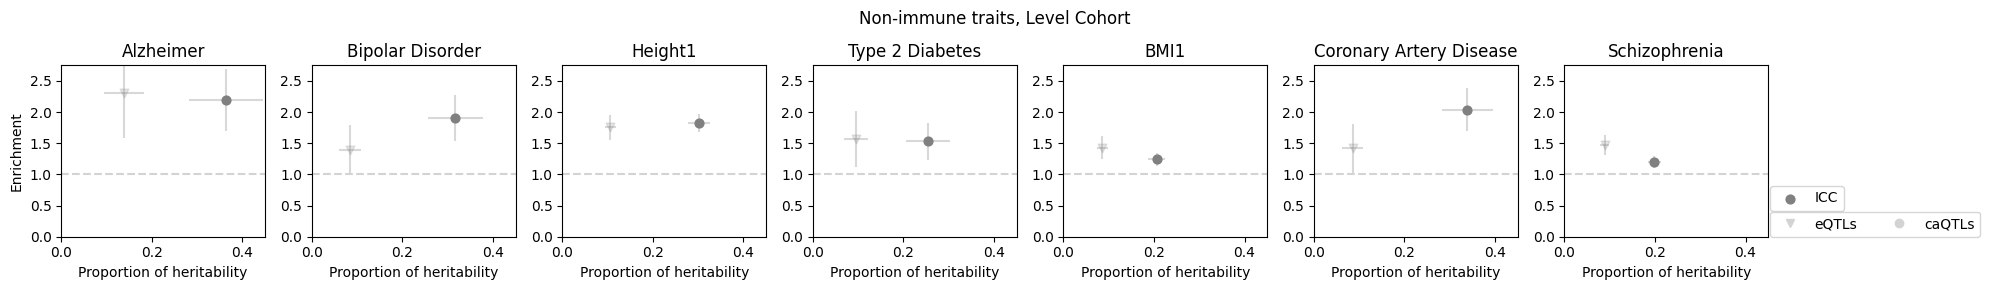

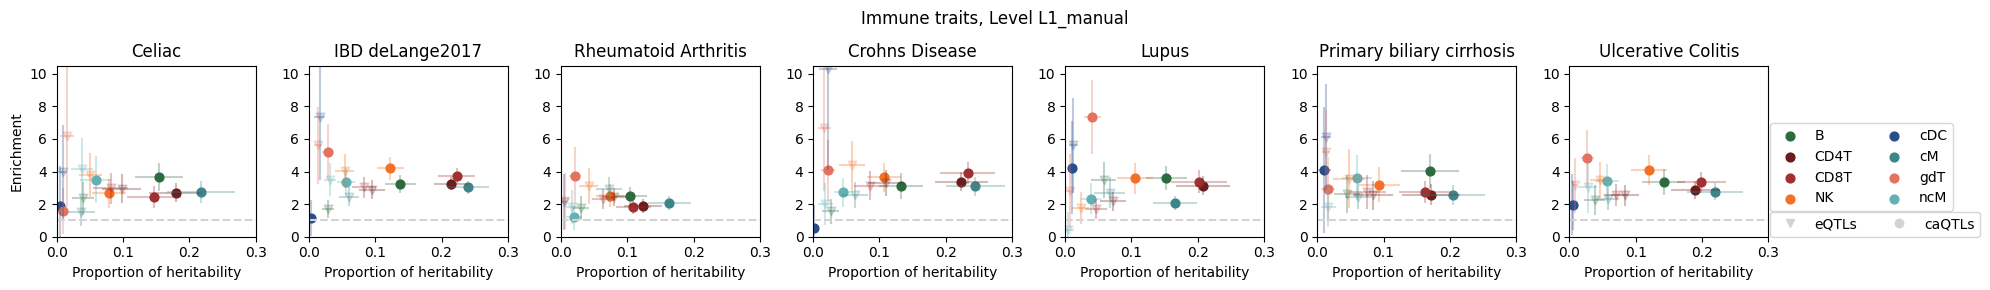

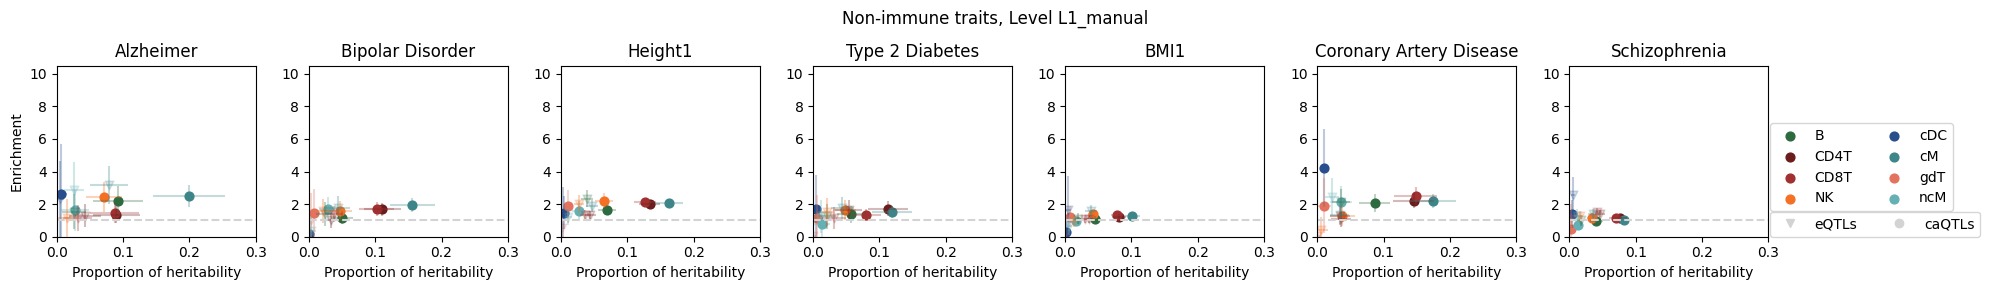

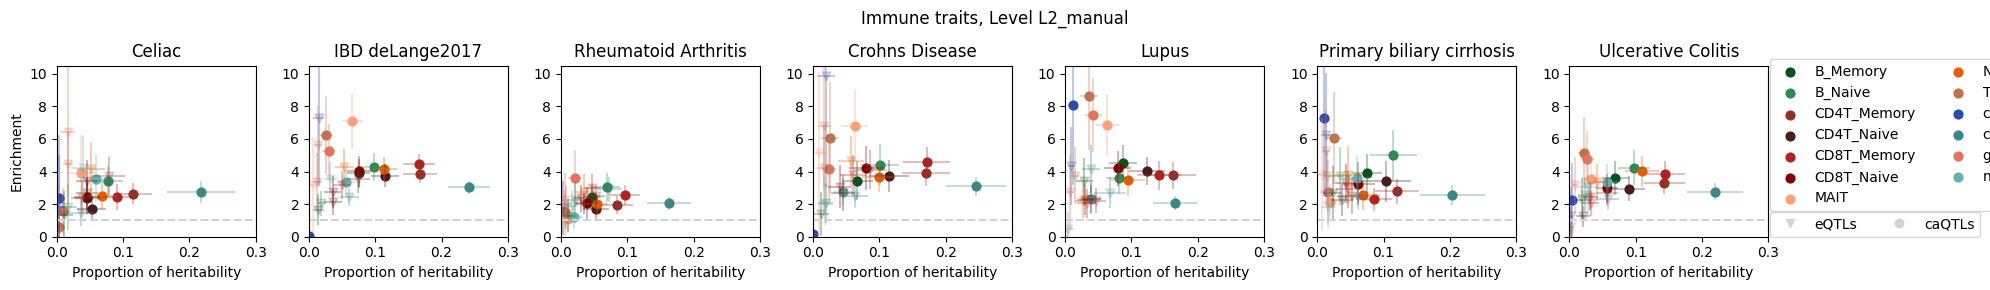

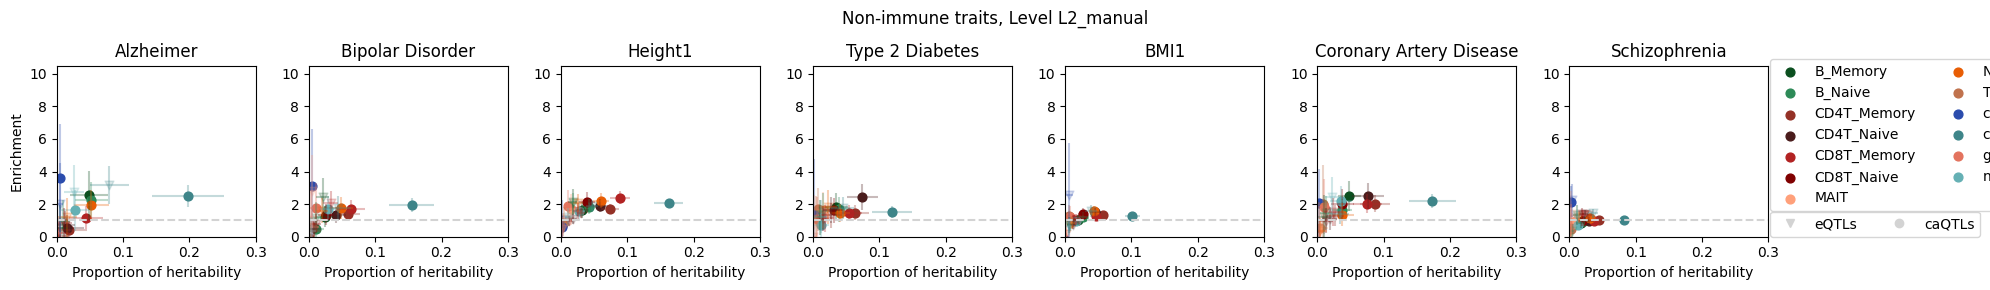

In [ ]:
for level in ldsc_results["Level"].unique():
    for trait_type, traits in traits_dict.items():
        fig, ax = plt.subplots(1, len(traits), figsize=(20, 3))
        for j, trait in enumerate(traits):
            tmp_df= ldsc_results[(ldsc_results["Trait"] == trait) & 
                                 (ldsc_results["Level"] == level)].groupby("Annotation")[["Prop._SNPs", "Prop._h2", "Enrichment", "Prop._h2_std_error", "Enrichment_std_error"]].mean()
            tmp_df = tmp_df.loc[(tmp_df.index.str.startswith("atac QTLs - significant - ")) | (tmp_df.index.str.startswith("rna QTLs - significant - "))]

            for i, row in tmp_df.iterrows():
                cell_type = i.split(" - ")[3]
                if "atac" in i:
                    marker = "o"
                    alpha = 1
                else:
                    marker = "v"
                    alpha = 0.2
                ax[j].errorbar(row["Prop._h2"], row["Enrichment"], xerr=row["Prop._h2_std_error"], yerr=row["Enrichment_std_error"],
                               c=cell_type_colors[level.split("_")[0]][cell_type], alpha=0.3) 
                            #    ms=40, label=cell_type if "atac" in i else None,
                            #    c=cell_type_colors[level.split("_")[0]][cell_type], marker=marker, alpha=alpha)
                ax[j].scatter(row["Prop._h2"], row["Enrichment"], s=40, label=cell_type if "atac" in i else None,
                              c=cell_type_colors[level.split("_")[0]][cell_type], marker=marker, alpha=alpha)
               
                

            if level == "Cohort":
                xlim = (0, 0.45)
                ylim = (0, 2.75)
            elif level == "L1_manual":
                xlim = (0, 0.3)
                ylim = (0, 10.5)
            elif level == "L2_manual":
                xlim = (0, 0.3)
                ylim = (0, 10.5)
            ax[j].hlines(y=1, xmin=0, xmax=xlim[1], color="lightgray", linestyle="--")
            ax[j].set_xlim(xlim)
            ax[j].set_ylim(ylim)

            trait_str = trait.replace('\n', ' ')
            ax[j].set_title(trait_str)
            ax[j].set_xlabel("Proportion of heritability")
            if j == 0:
                ax[j].set_ylabel("Enrichment")
        
        l1 = ax[j].legend(loc=(1.01,0.15), ncol=2)
        l2 = plt.legend(handles=[Line2D([0], [0], color="lightgray", marker="v", linestyle="none", label="eQTLs", alpha=1),
                                Line2D([0], [0], color="lightgray", marker="o", linestyle="none", label="caQTLs", alpha=1 )],
                        loc=(1.01,0), ncols=2)
        ax[j].add_artist(l1)

        plt.suptitle(f"{trait_type} traits, Level {level}", y=0.95)
        plt.tight_layout()
        plt.savefig(f"{fig_dir}/significant_qtl_heritability_enrichment_scatter_with_errorbars_{level}_{trait_type.lower()}_traits.png", bbox_inches='tight', dpi=300)
        plt.savefig(f"{fig_dir}/significant_qtl_heritability_enrichment_scatter_with_errorbars_{level}_{trait_type.lower()}_traits.pdf", bbox_inches='tight', dpi=300)

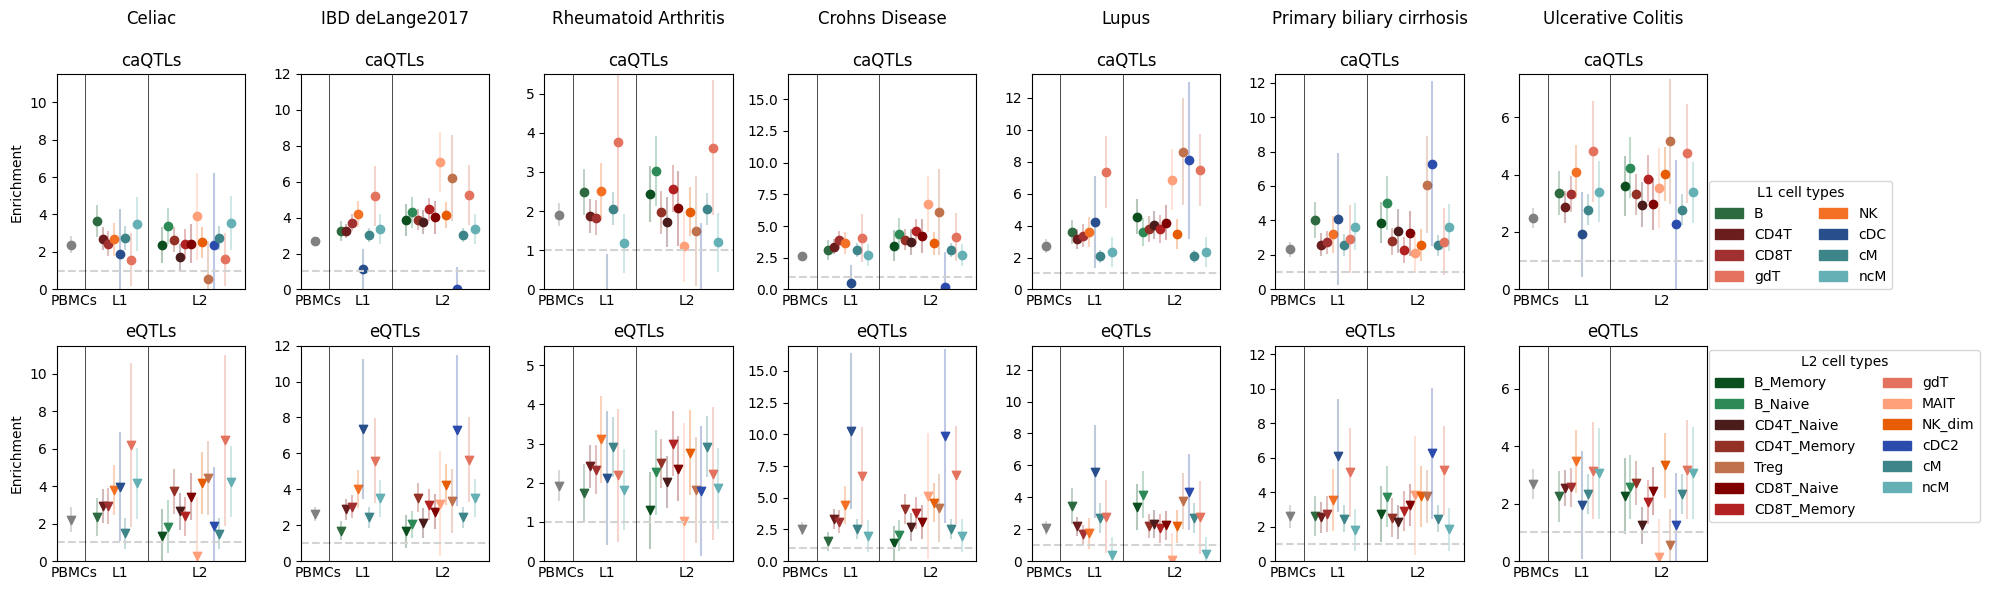

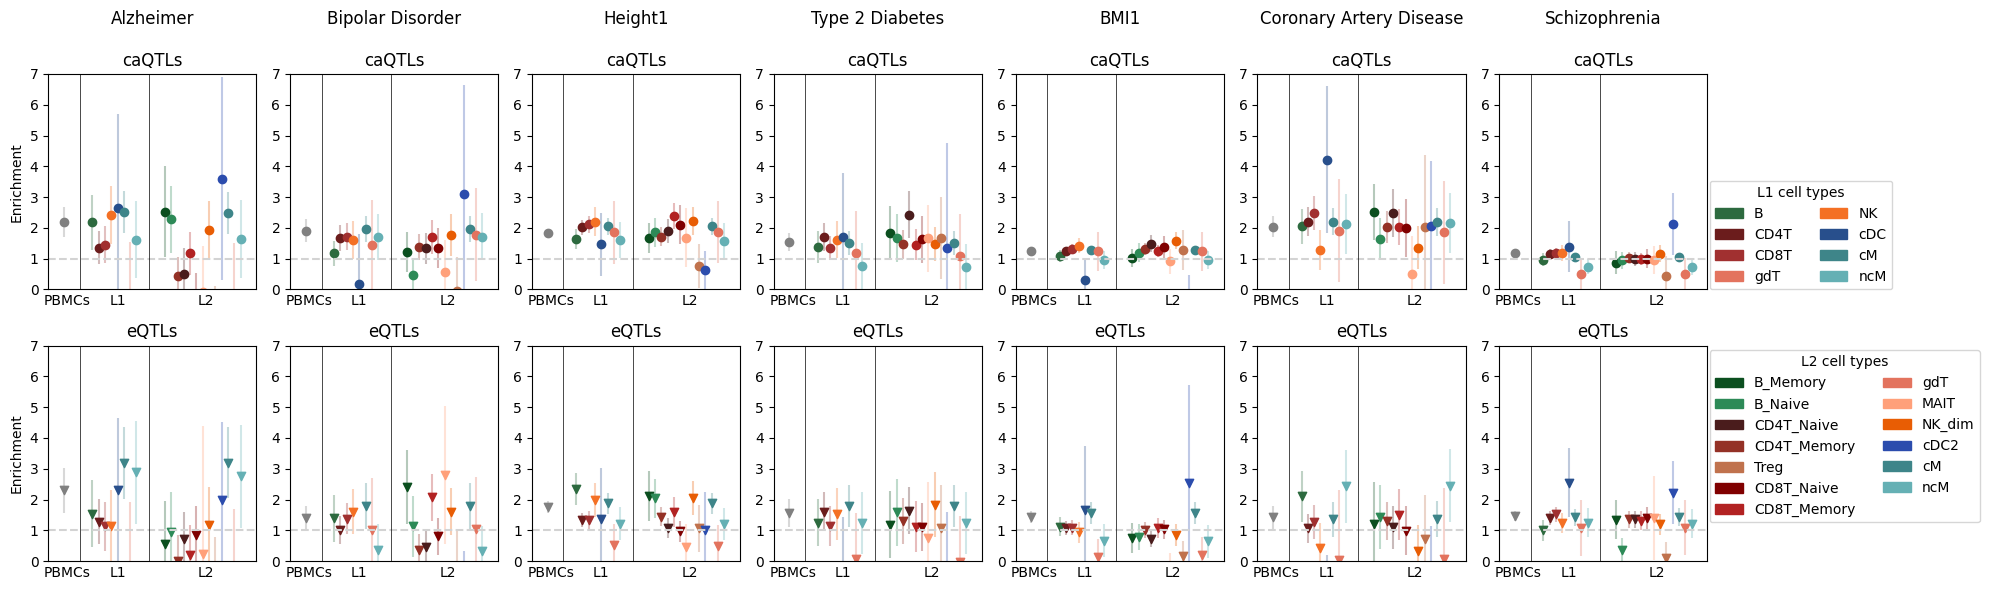

In [ ]:
ylims = {'Celiac': 11.5,
  'IBD\ndeLange2017': 12,
  'Rheumatoid\nArthritis': 5.5,
  'Crohns\nDisease': 17,
  'Lupus': 13.5,
  'Primary\nbiliary\ncirrhosis': 12.5,
  'Ulcerative\nColitis': 7.5}
dodge=0.1
x_per_level = {"Cohort": -0.3, "L1_manual": 0.5, "L2_manual": 1.9}

for trait_type, traits in traits_dict.items():
    fig, ax = plt.subplots(2, len(traits), figsize=(20, 6))
    for j, trait in enumerate(traits):
        tmp_df= ldsc_results[(ldsc_results["Trait"] == trait)].groupby(["Modality", "Level", "Cell type"])[["Prop._SNPs", "Enrichment", "Enrichment_std_error"]].mean().reset_index()

        for k, modality in enumerate(["atac", "rna"]):
            for i, level in enumerate(["Cohort", "L1_manual", "L2_manual"]):
                plot_df = tmp_df[(tmp_df["Modality"] == modality) & (tmp_df["Level"] == level)]
                plot_df = plot_df.reset_index()
                num_cell_types = len(plot_df)
                x_start = x_per_level[level] - ((dodge * num_cell_types) / 2)
                for l, row in plot_df.iterrows():
                    ax[k, j].scatter(
                        x=x_start + (dodge * l),
                        y=row["Enrichment"],
                        marker="o" if modality == "atac" else "v",
                        c=color_palette[row["Cell type"]],
                        alpha=1)
                    ax[k, j].errorbar(
                        x=x_start + (dodge * l),
                        y=row["Enrichment"],
                        yerr=row["Enrichment_std_error"],
                        fmt='none',
                        c=color_palette[row["Cell type"]],
                        alpha=0.3)
           
            if trait in ylims:
                ymax = ylims[trait]
            else:
                ymax = 7
            ax[k, j].hlines(y=1, xmin=-0.6, xmax=2.7, color="lightgray", linestyle="--")
            ax[k, j].vlines(x=-0.1, ymin=0, ymax=ymax, color="black", linewidth=0.5)
            ax[k, j].vlines(x=1, ymin=0, ymax=ymax, color="black", linewidth=0.5)
            ax[k, j].set_xlim(-0.6, 2.7)
            ax[k, j].set_ylim(0, ymax)
            
            ax[k, j].set_xticks(list(x_per_level.values()))
            ax[k, j].set_xticklabels(["PBMCs", "L1", "L2"])
            ax[k, j].tick_params(axis='x', which='both',length=0)

            trait_str = trait.replace('\n', ' ')
            if k == 0:
                ax[k, j].set_title(f"{trait_str}\n\ncaQTLs")
            else:
                ax[k, j].set_title("eQTLs")
            if j == 0:
                ax[k, j].set_ylabel("Enrichment")
            else:
                ax[k, j].set_xlabel("")

    L1_handles = []
    for cell_type, color in cell_type_colors["L1"].items():
        if cell_type in ldsc_results[ldsc_results["Level"] == "L1_manual"]["Cell type"].unique():
            L1_handles.append(mpatches.Patch(color=color, label=cell_type))
    L2_handles = []
    for cell_type, color in cell_type_colors["L2"].items():
        if cell_type in ldsc_results[ldsc_results["Level"] == "L2_manual"]["Cell type"].unique():
            L2_handles.append(mpatches.Patch(color=color, label=cell_type))
    ax[0, j].legend(handles=L1_handles, title="L1 cell types", loc=(1.01, 0), ncol=2)
    ax[1, j].legend(handles=L2_handles, title="L2 cell types", loc=(1.01, 0.18), ncol=2)

    plt.tight_layout()
    plt.savefig(f"{fig_dir}/significant_qtl_heritability_enrichment_by_level_with_errorbars_{trait_type.lower()}_traits.png", dpi=300)
    plt.savefig(f"{fig_dir}/significant_qtl_heritability_enrichment_by_level_with_errorbars_{trait_type.lower()}_traits.pdf", dpi=300)

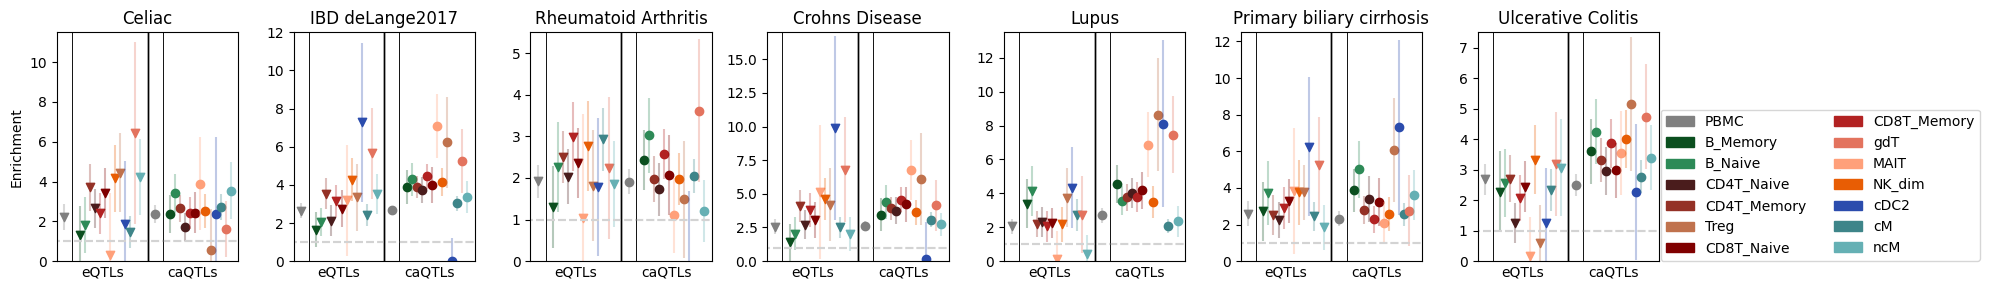

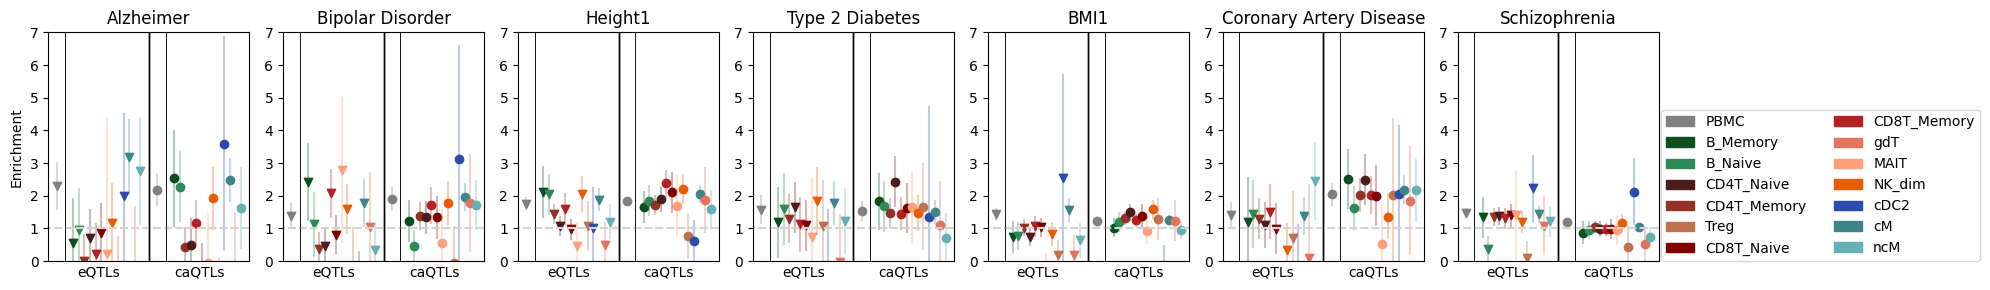

In [60]:
traits_dict = {"Immune": ldsc_results[ldsc_results["Trait type"] == "Immune"]["Trait"].unique(),
               "Non-immune": ldsc_results[ldsc_results["Trait type"] == "Non-immune"]["Trait"].unique()}
color_palette = cell_type_colors["Cohort"] | cell_type_colors["L1"] | cell_type_colors["L2"]
ylims = {'Celiac': 11.5,
  'IBD\ndeLange2017': 12,
  'Rheumatoid\nArthritis': 5.5,
  'Crohns\nDisease': 17,
  'Lupus': 13.5,
  'Primary\nbiliary\ncirrhosis': 12.5,
  'Ulcerative\nColitis': 7.5}
dodge=0.1
x_per_level = {"Cohort": -0.3, "L2_manual": 0.6}

for trait_type, traits in traits_dict.items():
    fig, ax = plt.subplots(1, len(traits), figsize=(20, 3))
    for j, trait in enumerate(traits):
        tmp_df= ldsc_results[(ldsc_results["Trait"] == trait)].groupby(["Modality", "Level", "Cell type"])[["Prop._SNPs", "Enrichment", "Enrichment_std_error"]].mean().reset_index()

        for k, modality in enumerate(["rna", "atac"]):
            for i, level in enumerate(["Cohort", "L2_manual"]):
                plot_df = tmp_df[(tmp_df["Modality"] == modality) & (tmp_df["Level"] == level)]
                plot_df = plot_df.reset_index()
                num_cell_types = len(plot_df)
                # x_start = 0.5*
                x_start = (x_per_level[level] - ((dodge * num_cell_types) / 2)) + (1.8*k)
                for l, row in plot_df.iterrows():
                    ax[j].scatter(
                        x=x_start + (dodge * l),
                        y=row["Enrichment"],
                        marker="o" if modality == "atac" else "v",
                        c=color_palette[row["Cell type"]],
                        alpha=1)
                    ax[j].errorbar(
                        x=x_start + (dodge * l),
                        y=row["Enrichment"],
                        yerr=row["Enrichment_std_error"],
                        fmt='none',
                        c=color_palette[row["Cell type"]],
                        alpha=0.3)
           
            if trait in ylims:
                ymax = ylims[trait]
            else:
                ymax = 7
            ax[j].hlines(y=1, xmin=-0.6, xmax=3.2, color="lightgray", linestyle="--")
            ax[j].vlines(x=-0.2, ymin=0, ymax=ymax, color="black", linewidth=0.5)
            ax[j].vlines(x=1.3, ymin=0, ymax=ymax, color="black", linewidth=1)
            ax[j].vlines(x=1.6, ymin=0, ymax=ymax, color="black", linewidth=0.5)
            ax[j].set_xlim(-0.5, 3.1)
            ax[j].set_ylim(0, ymax)
            
            ax[j].set_xticks([0.4, 2.2])
            ax[j].set_xticklabels(["eQTLs", "caQTLs"])
            ax[j].tick_params(axis='x', which='both',length=0)

            trait_str = trait.replace('\n', ' ')
            ax[j].set_title(trait_str)
            if j == 0:
                ax[j].set_ylabel("Enrichment")
            else:
                ax[j].set_xlabel("")

    L2_handles = []
    L2_handles.append(mpatches.Patch(color=cell_type_colors["Cohort"]["ICC"], label="PBMC"))
    for cell_type, color in cell_type_colors["L2"].items():
        if cell_type in ldsc_results[ldsc_results["Level"] == "L2_manual"]["Cell type"].unique():
            L2_handles.append(mpatches.Patch(color=color, label=cell_type))
    ax[j].legend(handles=L2_handles, loc=(1.01, 0), ncol=2)

    plt.tight_layout()
    plt.savefig(f"{fig_dir}/significant_qtl_heritability_enrichment_Cohort_L2_with_errorbars_{trait_type.lower()}_traits.png", dpi=300)
    plt.savefig(f"{fig_dir}/significant_qtl_heritability_enrichment_Cohort_L2_with_errorbars_{trait_type.lower()}_traits.pdf", dpi=300)

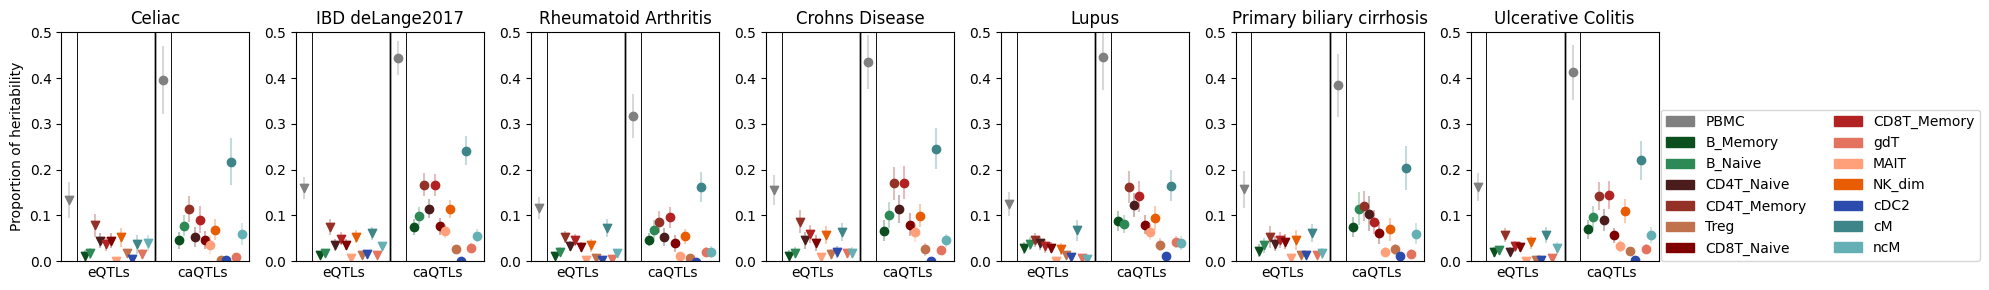

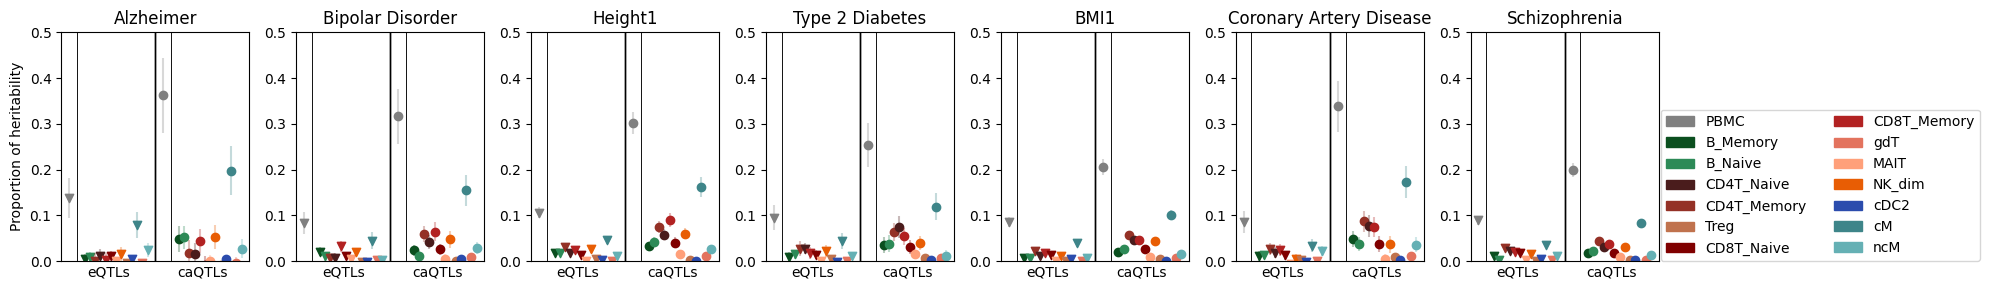

In [64]:
traits_dict = {"Immune": ldsc_results[ldsc_results["Trait type"] == "Immune"]["Trait"].unique(),
               "Non-immune": ldsc_results[ldsc_results["Trait type"] == "Non-immune"]["Trait"].unique()}
color_palette = cell_type_colors["Cohort"] | cell_type_colors["L1"] | cell_type_colors["L2"]
dodge=0.1
x_per_level = {"Cohort": -0.3, "L2_manual": 0.6}

for trait_type, traits in traits_dict.items():
    fig, ax = plt.subplots(1, len(traits), figsize=(20, 3))
    for j, trait in enumerate(traits):
        tmp_df= ldsc_results[(ldsc_results["Trait"] == trait)].groupby(["Modality", "Level", "Cell type"])[["Prop._SNPs", "Prop._h2", "Prop._h2_std_error"]].mean().reset_index()

        for k, modality in enumerate(["rna", "atac"]):
            for i, level in enumerate(["Cohort", "L2_manual"]):
                plot_df = tmp_df[(tmp_df["Modality"] == modality) & (tmp_df["Level"] == level)]
                plot_df = plot_df.reset_index()
                num_cell_types = len(plot_df)
                # x_start = 0.5*
                x_start = (x_per_level[level] - ((dodge * num_cell_types) / 2)) + (1.8*k)
                for l, row in plot_df.iterrows():
                    ax[j].scatter(
                        x=x_start + (dodge * l),
                        y=row["Prop._h2"],
                        marker="o" if modality == "atac" else "v",
                        c=color_palette[row["Cell type"]],
                        alpha=1)
                    ax[j].errorbar(
                        x=x_start + (dodge * l),
                        y=row["Prop._h2"],
                        yerr=row["Prop._h2_std_error"],
                        fmt='none',
                        c=color_palette[row["Cell type"]],
                        alpha=0.3)
           
            ymax = 0.5
            ax[j].vlines(x=-0.2, ymin=0, ymax=ymax, color="black", linewidth=0.5)
            ax[j].vlines(x=1.3, ymin=0, ymax=ymax, color="black", linewidth=1)
            ax[j].vlines(x=1.6, ymin=0, ymax=ymax, color="black", linewidth=0.5)
            ax[j].set_xlim(-0.5, 3.1)
            ax[j].set_ylim(0, ymax)
            
            ax[j].set_xticks([0.4, 2.2])
            ax[j].set_xticklabels(["eQTLs", "caQTLs"])
            ax[j].tick_params(axis='x', which='both',length=0)

            trait_str = trait.replace('\n', ' ')
            ax[j].set_title(trait_str)
            if j == 0:
                ax[j].set_ylabel("Proportion of heritability")
            else:
                ax[j].set_xlabel("")

    L2_handles = []
    L2_handles.append(mpatches.Patch(color=cell_type_colors["Cohort"]["ICC"], label="PBMC"))
    for cell_type, color in cell_type_colors["L2"].items():
        if cell_type in ldsc_results[ldsc_results["Level"] == "L2_manual"]["Cell type"].unique():
            L2_handles.append(mpatches.Patch(color=color, label=cell_type))
    ax[j].legend(handles=L2_handles, loc=(1.01, 0), ncol=2)

    plt.tight_layout()
    plt.savefig(f"{fig_dir}/significant_qtl_heritability_prop_h2_Cohort_L2_with_errorbars_{trait_type.lower()}_traits.png", dpi=300)
    plt.savefig(f"{fig_dir}/significant_qtl_heritability_prop_h2_Cohort_L2_with_errorbars_{trait_type.lower()}_traits.pdf", dpi=300)

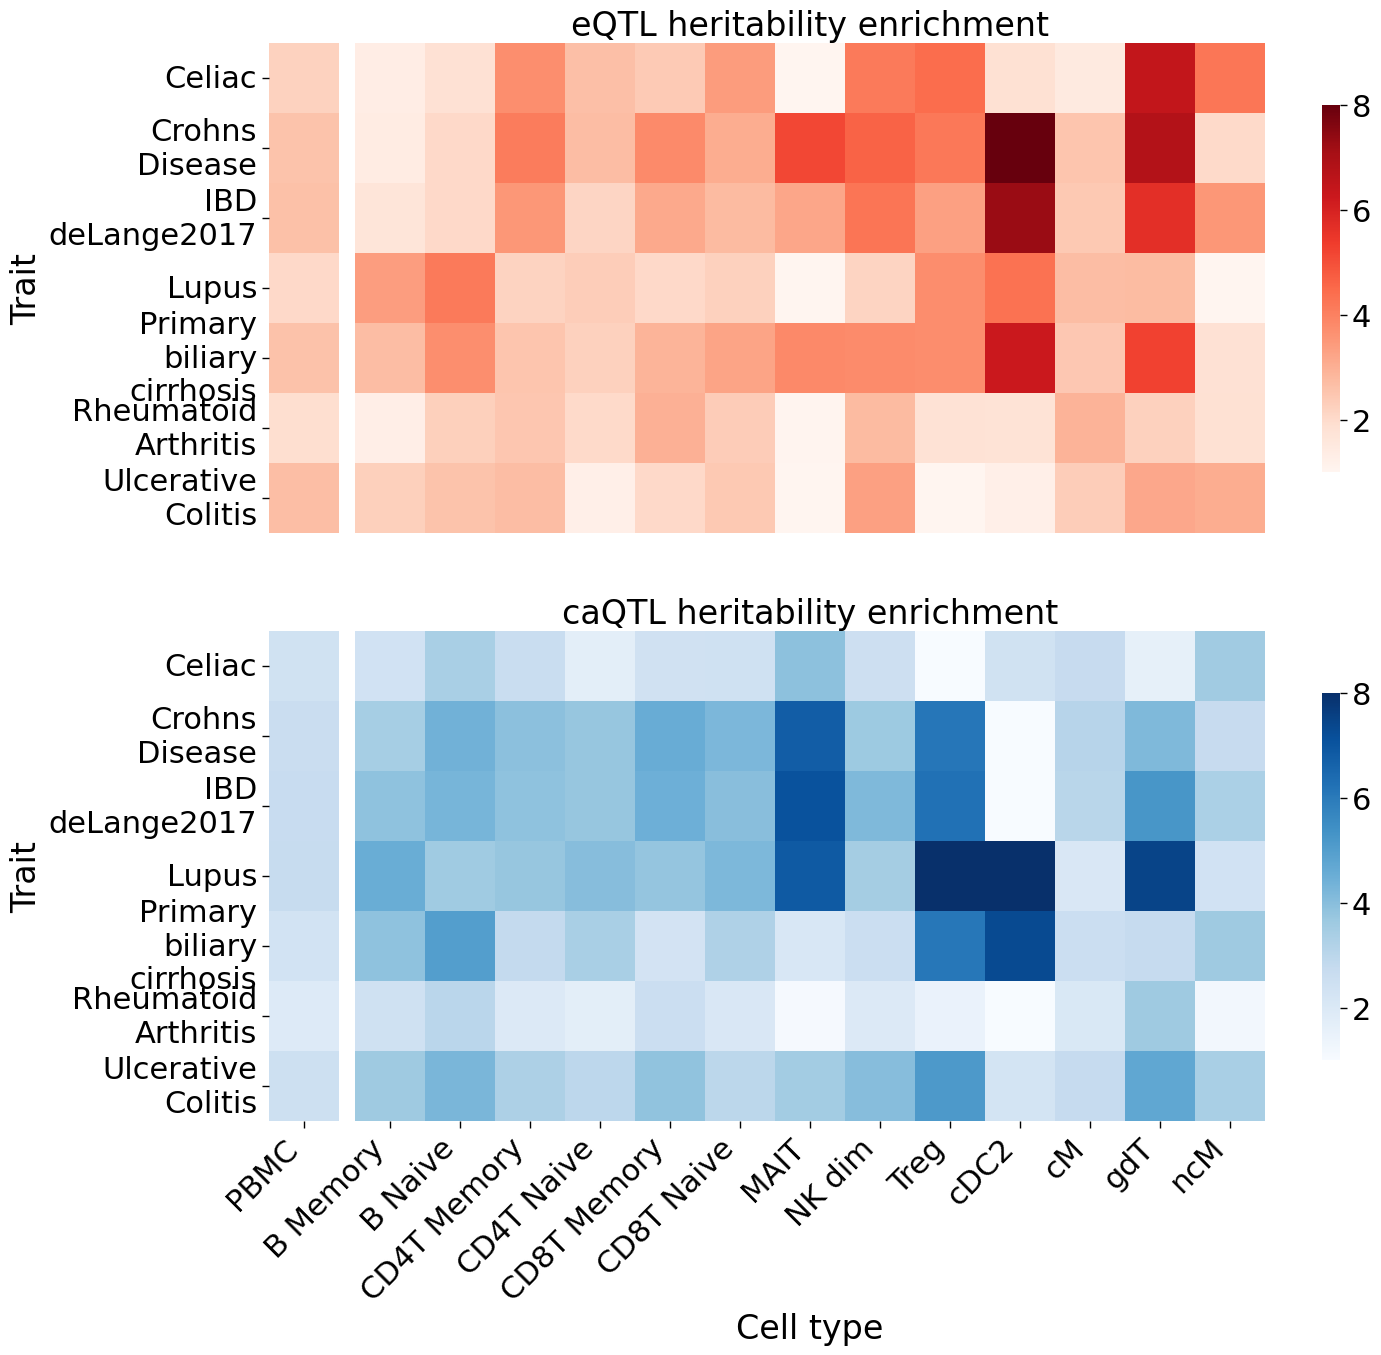

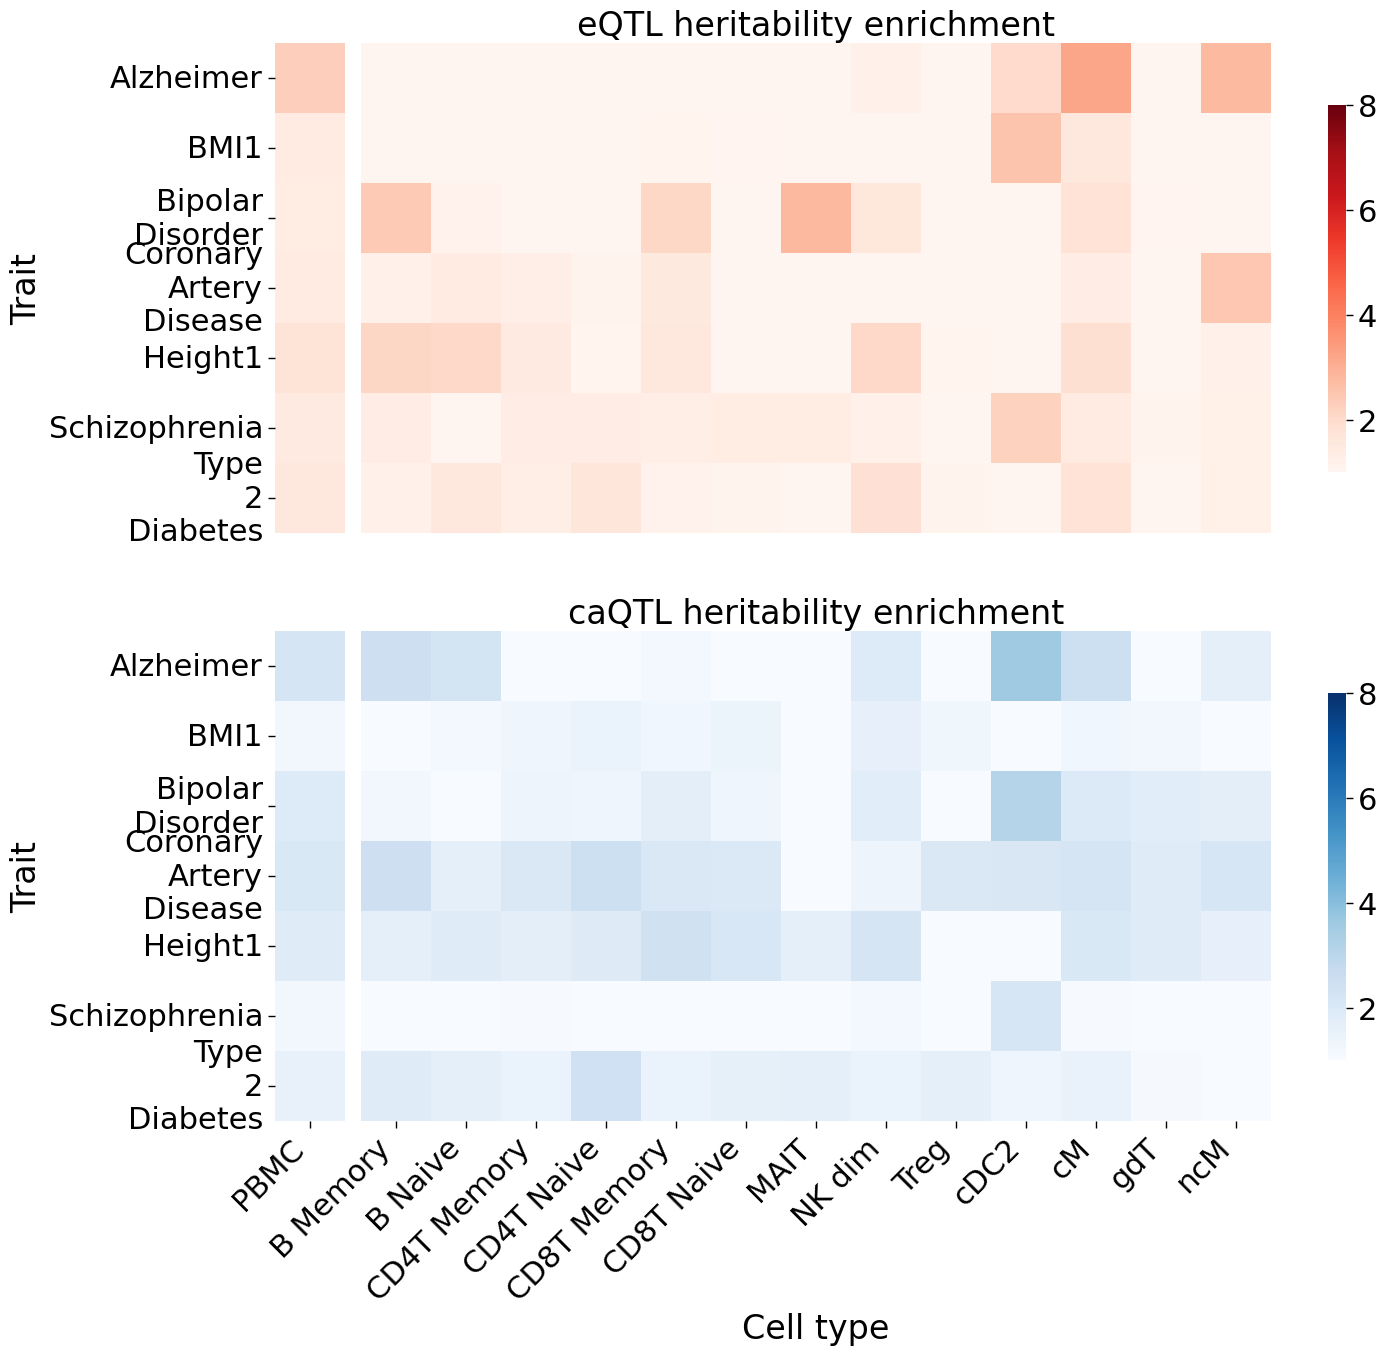

In [46]:
sns.set_context("paper", font_scale=2.5)

for trait_type in ["Immune", "Non-immune"]:
    fig, ax = plt.subplots(2, 2, figsize=(16, 14), gridspec_kw={'width_ratios': [0.09, 1]})
    plt.subplots_adjust(wspace=0)
    for j, level in enumerate(["Cohort", "L2_manual"]):
        for i, modality in enumerate(["rna","atac"]):
            plot_df = ldsc_results[(ldsc_results["Level"] == level) & 
                        (ldsc_results["Modality"] == modality) & 
                        (ldsc_results["Trait type"] == trait_type)].pivot(index="Trait", columns="Cell type", values="Enrichment")
            plot_df.columns = [c.replace("_", " ") for c in plot_df.columns]

            sns.heatmap(plot_df,
                        cmap="Blues" if modality == "atac" else "Reds", 
                        cbar=True if level == "L2_manual" else False,
                        cbar_kws={"shrink": 0.75},
                        square=True, ax=ax[i, j], vmin=1, vmax=8)
            if modality == "rna":
                if level == "L2_manual":
                    ax[i, j].set_title("eQTL heritability enrichment")
                ax[i, j].set_xticks([])
            else: 
                if level == "L2_manual":
                    ax[i, j].set_title("caQTL heritability enrichment")
                    ax[i, j].set_xlabel("Cell type")
                    ax[i, j].set_xticklabels(ax[i, j].get_xticklabels(), rotation=45, ha='right')
                else:
                    ax[i, j].set_xticklabels(["PBMC"], rotation=45, ha='right')
            
            if level == "L2_manual":
                ax[i, j].set_ylabel("")
                ax[i, j].set_yticks([])
            

    plt.savefig(f"{fig_dir}/significant_qtl_heritability_enrichment_heatmap_Cohort_L2_{trait_type.lower()}_traits.png", dpi=300)
    plt.savefig(f"{fig_dir}/significant_qtl_heritability_enrichment_heatmap_Cohort_L2_{trait_type.lower()}_traits.pdf", dpi=300)

In [ ]:
# modality specific QTLs

# read in results
ldsc_results = []
for trait in all_traits:
    for level in cell_types_dict.keys():
        for annot in ["significant_qtls_pooled_rna_and_atac", "significant_qtls_pooled_rna_only", "significant_qtls_pooled_atac_only"]:
            try:
                df = pd.read_csv(
                    f"{results_dir}/{trait}_{level}_all_cell_types.{annot}.results",
                    sep="\t", index_col=0)
                df = df[-1::]
                df["Trait"] = trait.replace("_", "\n")
                if trait in immune_traits:
                    df["Trait type"] = "Immune"
                else:
                    df["Trait type"] = "Non-immune"
                df["Level"] = level
                df["Annot"] = annot
                ldsc_results.append(df) 
            except:
                print(f"No results found for {trait}_{level}_all_cell_types.{annot}.results")
                continue
        
ldsc_results = pd.concat(ldsc_results)
ldsc_results.reset_index(inplace=True, drop=True)

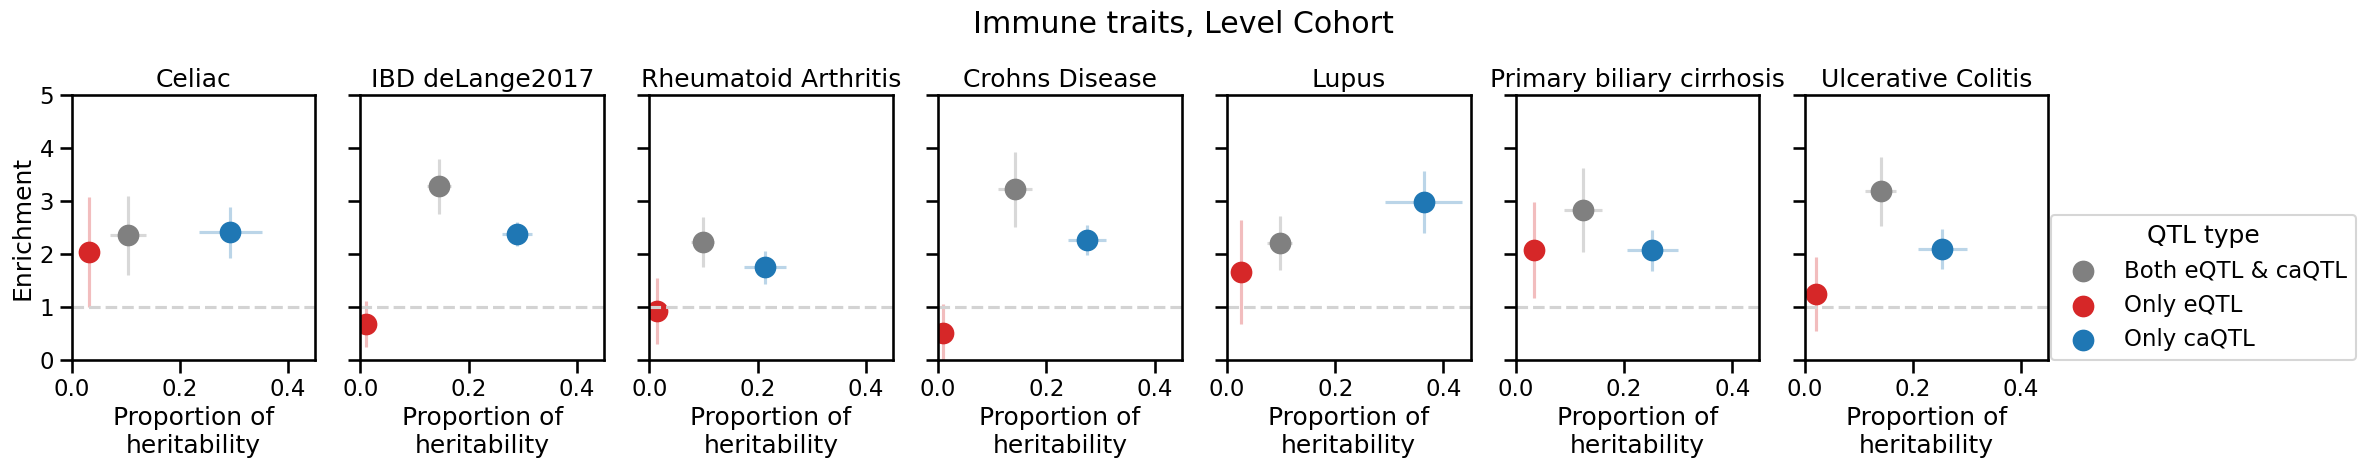

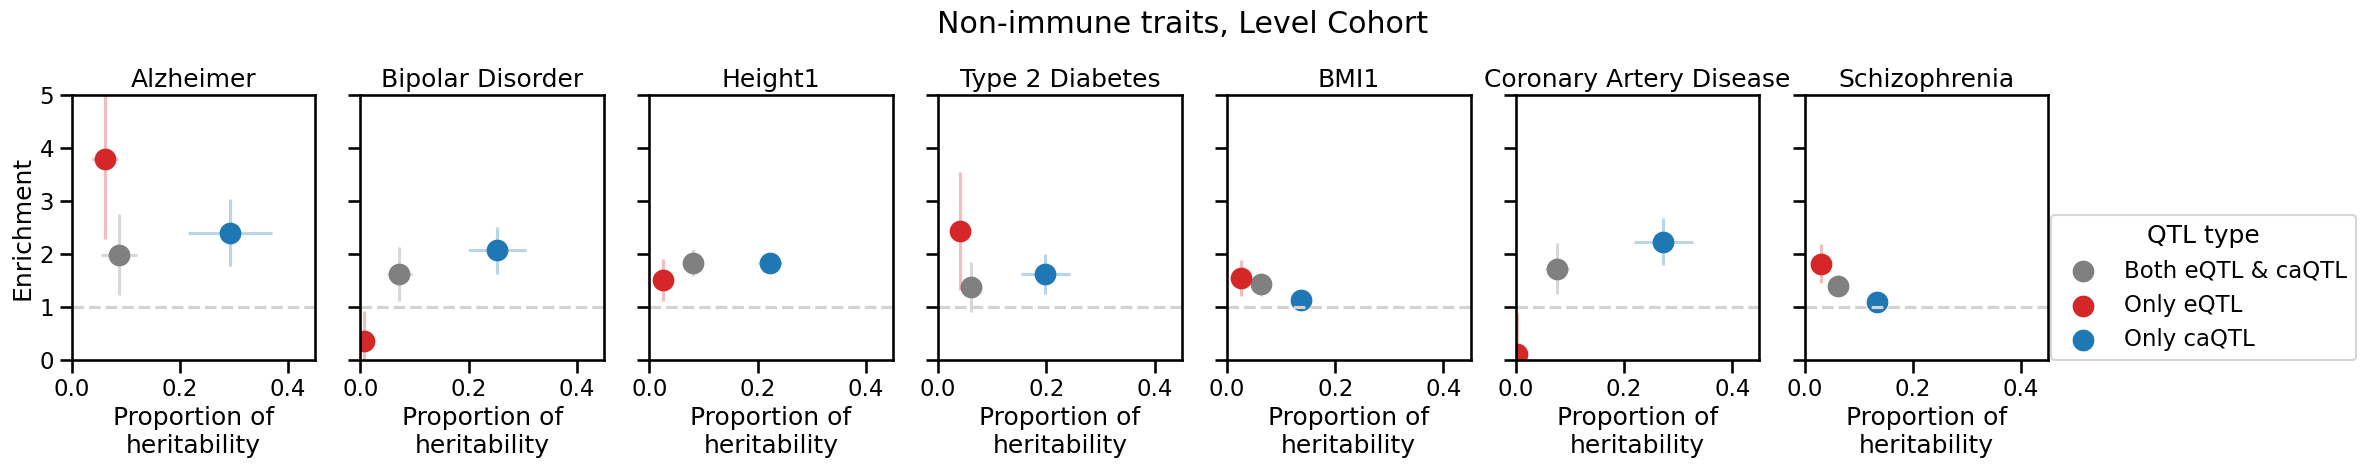

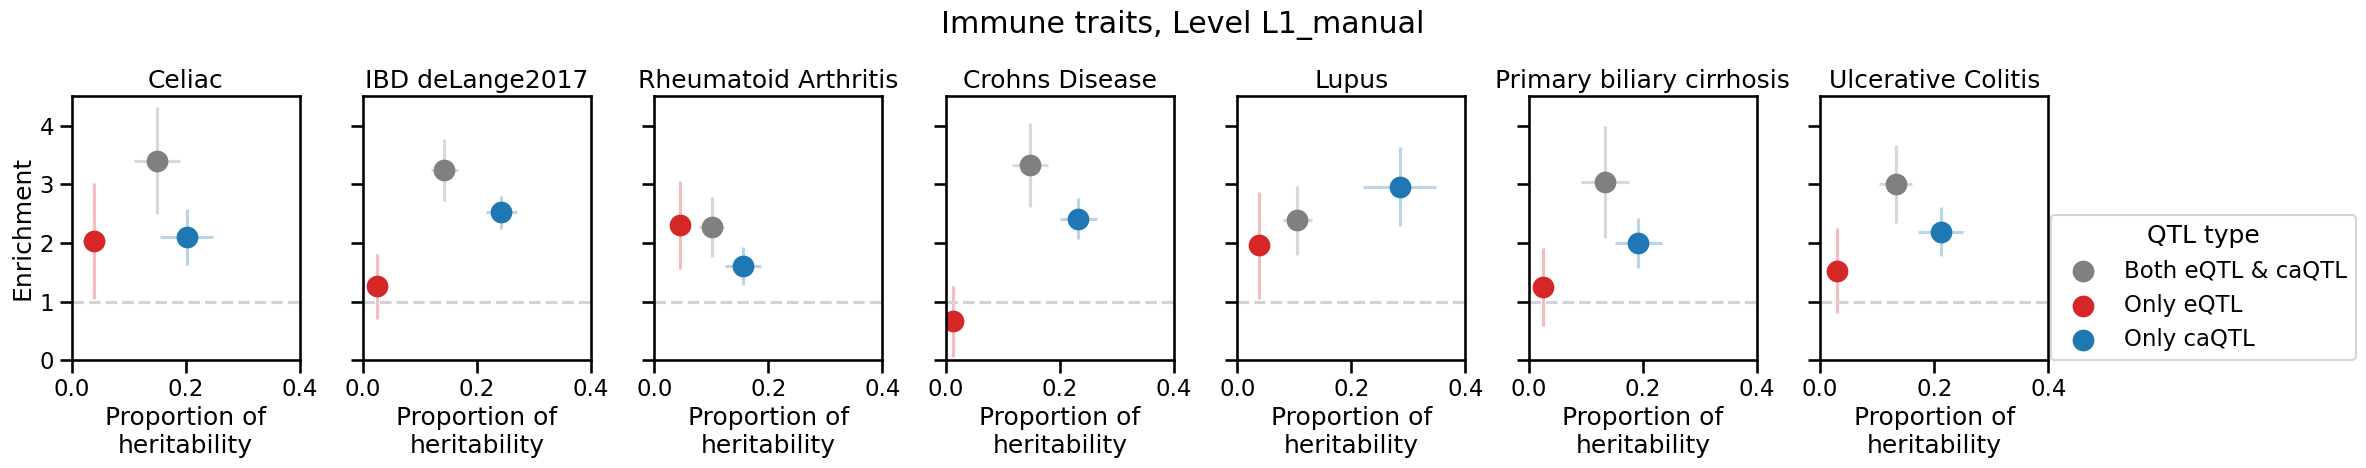

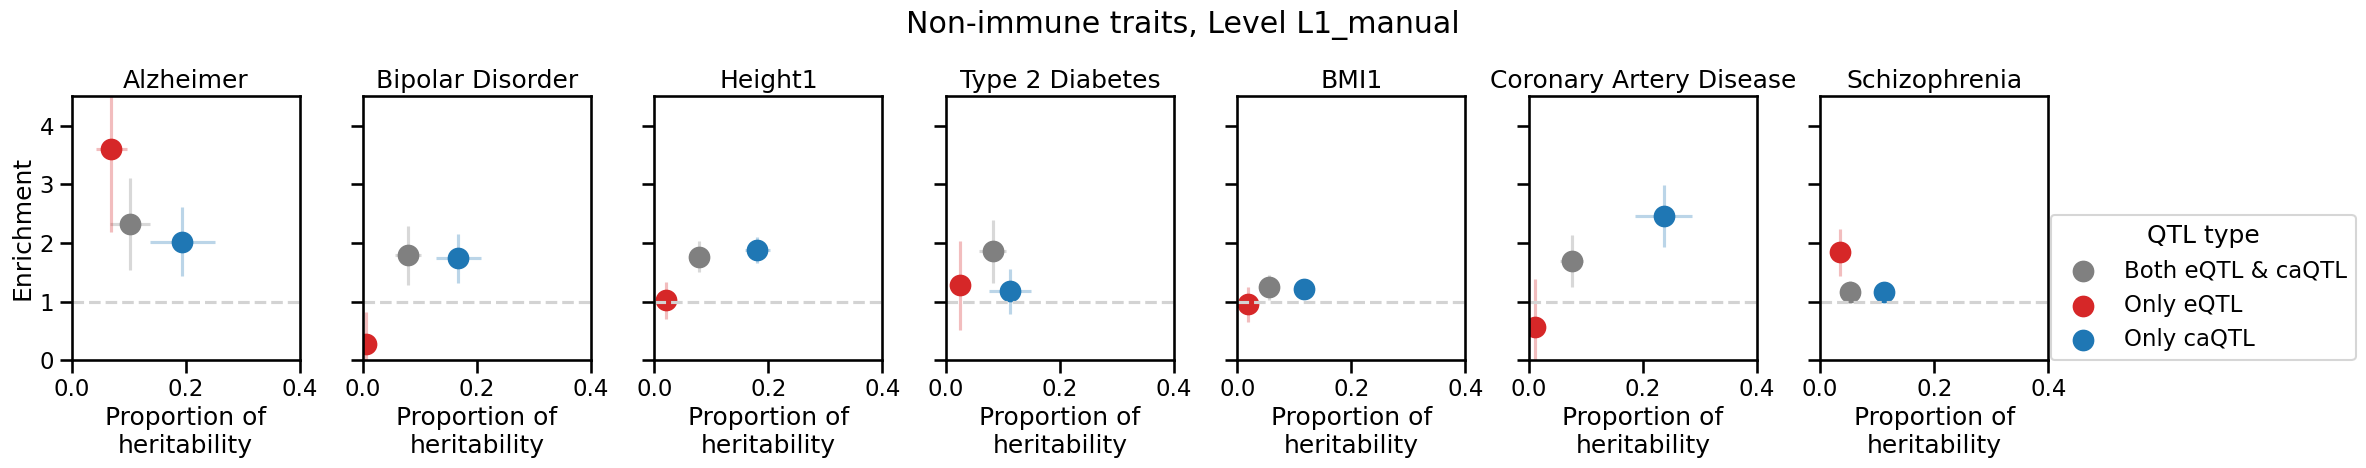

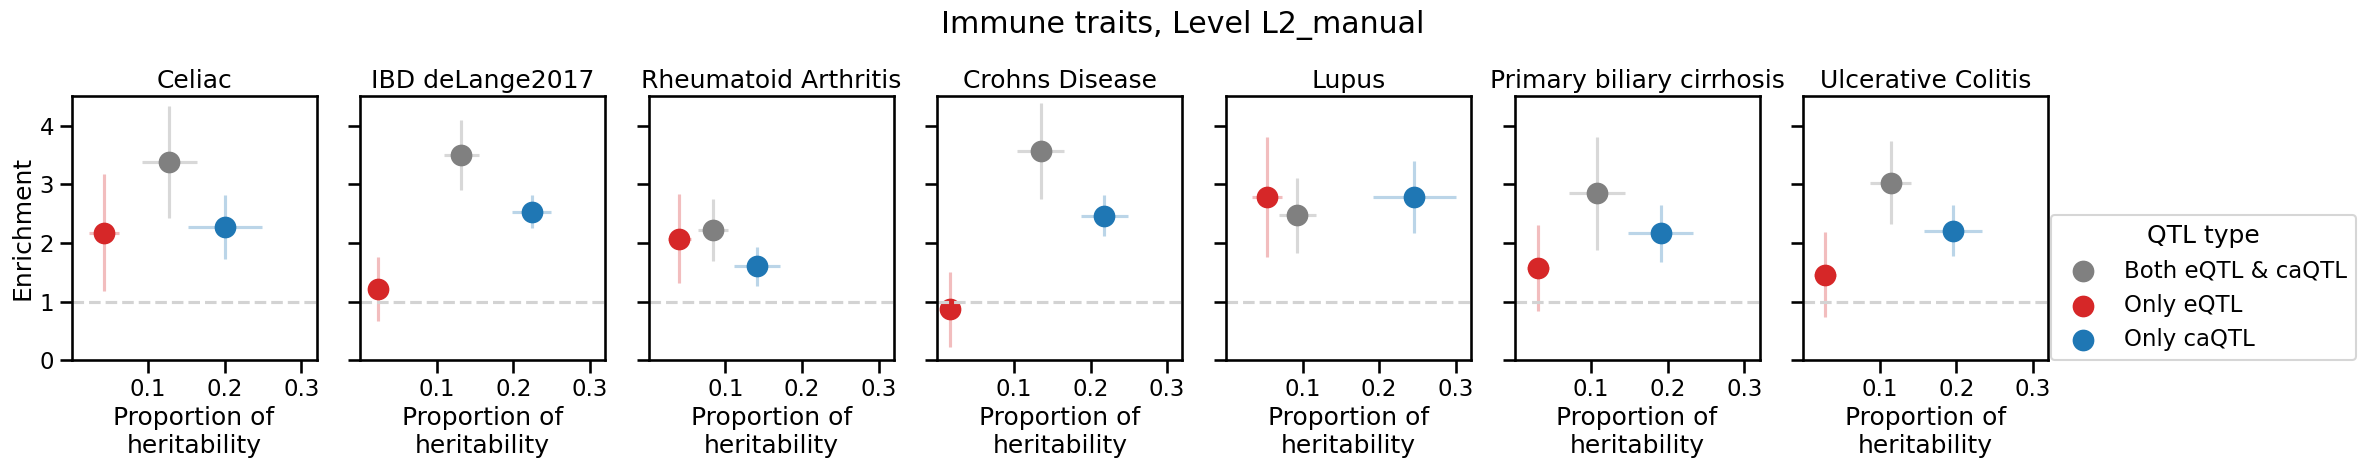

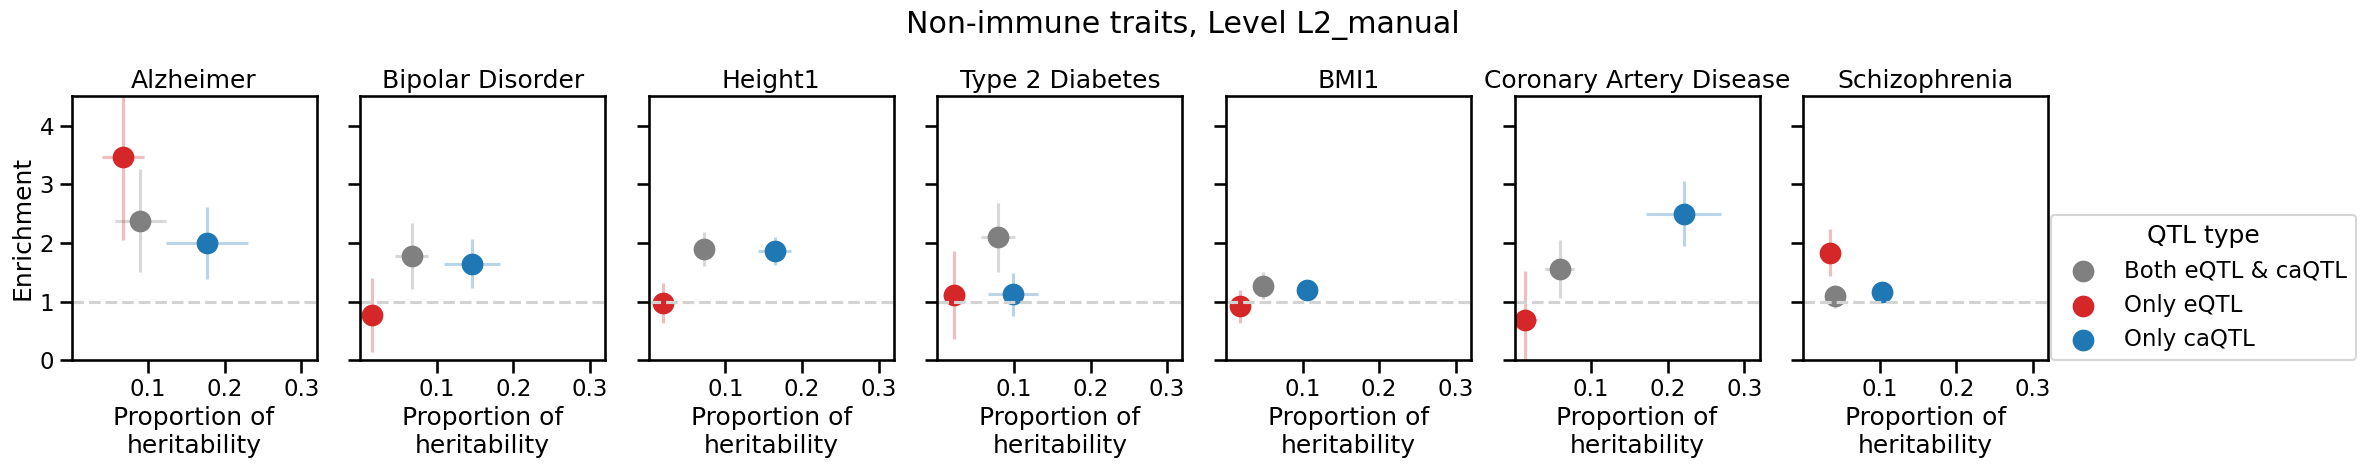

In [14]:
sns.set_context("talk", font_scale=1)

traits_dict = {"Immune": ldsc_results[ldsc_results["Trait type"] == "Immune"]["Trait"].unique(),
               "Non-immune": ldsc_results[ldsc_results["Trait type"] == "Non-immune"]["Trait"].unique()}

for level in ldsc_results["Level"].unique():
    for trait_type, traits in traits_dict.items():
        fig, ax = plt.subplots(1, len(traits), figsize=(24, 5))
        for j, trait in enumerate(traits):
            tmp_df= ldsc_results[(ldsc_results["Trait"] == trait) & 
                                 (ldsc_results["Level"] == level)]
            for i, row in tmp_df.iterrows():
                if "rna_and_atac" in row["Annot"]:
                    color = "gray"
                    label = "Both eQTL & caQTL"
                    marker = "o"
                elif "rna_only" in row["Annot"]:
                    color = "tab:red"
                    label = "Only eQTL"
                    marker = "o"
                elif "atac_only" in row["Annot"]:
                    color = "tab:blue"
                    label = "Only caQTL"
                    marker = "o"

                    
                ax[j].errorbar(row["Prop._h2"], row["Enrichment"], xerr=row["Prop._h2_std_error"], yerr=row["Enrichment_std_error"],
                               c=color, alpha=0.3) 
                ax[j].scatter(row["Prop._h2"], row["Enrichment"], s=200,
                              c=color,  marker=marker, label=label)
               
            if level == "Cohort":
                xlim = (0, 0.45)
                ylim = (0, 5)
            elif level == "L1_manual":
                xlim = (0, 0.4)
                ylim = (0, 4.5)
            elif level == "L2_manual":
                xlim = (0, 0.32)
                ylim = (0, 4.5)
            ax[j].hlines(y=1, xmin=0, xmax=xlim[1], color="lightgray", linestyle="--")
            ax[j].set_xlim(xlim)
            ax[j].set_ylim(ylim)
            if level == "L2_manual":
                ax[j].set_xticks([0.1, 0.2, 0.3])

            trait_str = trait.replace('\n', ' ')
            ax[j].set_title(trait_str)
            ax[j].set_xlabel("Proportion of\nheritability")
            if j == 0:
                ax[j].set_ylabel("Enrichment")
            else:
                ax[j].set_yticklabels([])
        
        ax[j].legend(loc=(1.01,0), title="QTL type")

        plt.suptitle(f"{trait_type} traits, Level {level}", y=0.95)
        plt.tight_layout()
        plt.savefig(f"{fig_dir}/significant_qtls_across_all_cell_types_modality_specific_heritability_enrichment_scatter_with_errorbars_{level}_{trait_type.lower()}_traits.png", bbox_inches='tight', dpi=300)
        plt.savefig(f"{fig_dir}/significant_qtls_across_all_cell_types_modality_specific_heritability_enrichment_scatter_with_errorbars_{level}_{trait_type.lower()}_traits.pdf", bbox_inches='tight', dpi=300)